In [4]:
import cv2
import matplotlib.pyplot as plt
import numpy as np


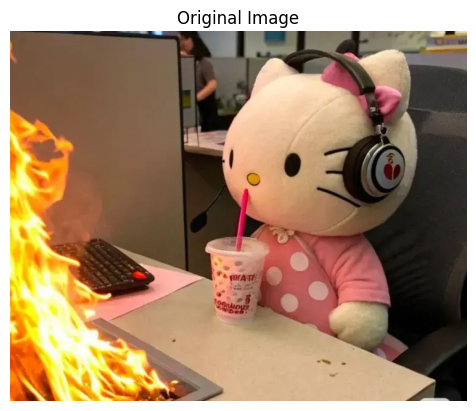

In [5]:
image = cv2.imread('/content/hello-kitty-on-fire.jpg')

if image is None:
    print("Image not found")
else:
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.imshow(image)
    plt.title('Original Image')
    plt.axis('off')
    plt.show()

In [6]:
row, col, ch = image.shape

data = image.reshape((-1, 3))
data = np.float32(data)

print(data.shape)


(444600, 3)


In [7]:
K = 3

np.random.seed(42)

random_indices = np.random.choice(
    len(data), K, replace=False
)

centers = data[random_indices].copy()

print("Initial Centers:")
print(centers)

Initial Centers:
[[118.  58.  22.]
 [  6.   6.   4.]
 [253. 254. 116.]]


In [8]:
distances = np.zeros((len(data), K))

for i in range(K):
    distances[:, i] = np.sqrt(
        np.sum((data - centers[i]) ** 2, axis=1)
    )

labels = np.argmin(distances, axis=1)

In [9]:
new_centers = np.zeros((K, 3))

for i in range(K):
    cluster_pixels = data[labels == i]

    if len(cluster_pixels) > 0:
        new_centers[i] = np.mean(cluster_pixels, axis=0)
    else:
        new_centers[i] = centers[i]

centers = new_centers

print("Updated Centers:")
print(centers)

Updated Centers:
[[132.31910706  90.6601944   67.8817749 ]
 [ 29.14742279  22.91193008  17.10920143]
 [225.8331604  186.37721252 127.16270447]]


In [10]:
for iteration in range(100):

    distances = np.zeros((len(data), K))

    for i in range(K):
        distances[:, i] = np.sqrt(
            np.sum((data - centers[i]) ** 2, axis=1)
        )

    labels = np.argmin(distances, axis=1)

    new_centers = np.zeros((K, 3))

    for i in range(K):
        cluster_pixels = data[labels == i]

        if len(cluster_pixels) > 0:
            new_centers[i] = np.mean(cluster_pixels, axis=0)
        else:
            new_centers[i] = centers[i]

    if np.allclose(centers, new_centers):
        centers = new_centers
        print("Converged at iteration:", iteration + 1)
        break

    centers = new_centers

print("Final Centers:")
print(centers)

Converged at iteration: 11
Final Centers:
[[141.32995605  96.73607635  72.62463379]
 [ 40.42176819  30.7863102   23.45857239]
 [225.90623474 185.38366699 126.10561371]]


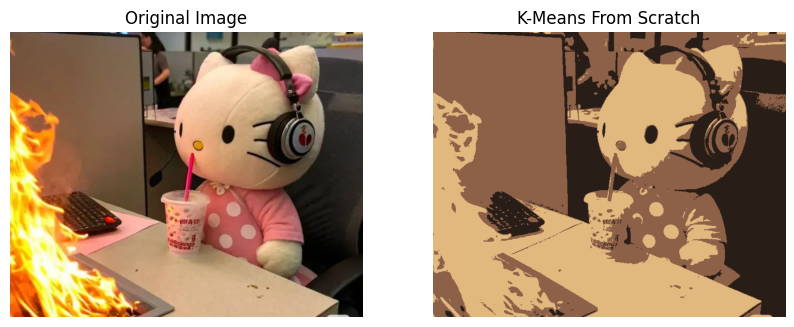

In [11]:
centers = np.uint8(centers)

segmented_image = centers[labels]
segmented_image = segmented_image.reshape((row, col, ch))

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(segmented_image)
plt.title("K-Means From Scratch")
plt.axis("off")

plt.show()